<a href="https://colab.research.google.com/github/andyotani/PCVK_Ganjil_26-27/blob/main/Jobsheet07/JS07_pcvk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Praktikum Segmentasi Citra dengan Thresholding

Tugas Individu

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

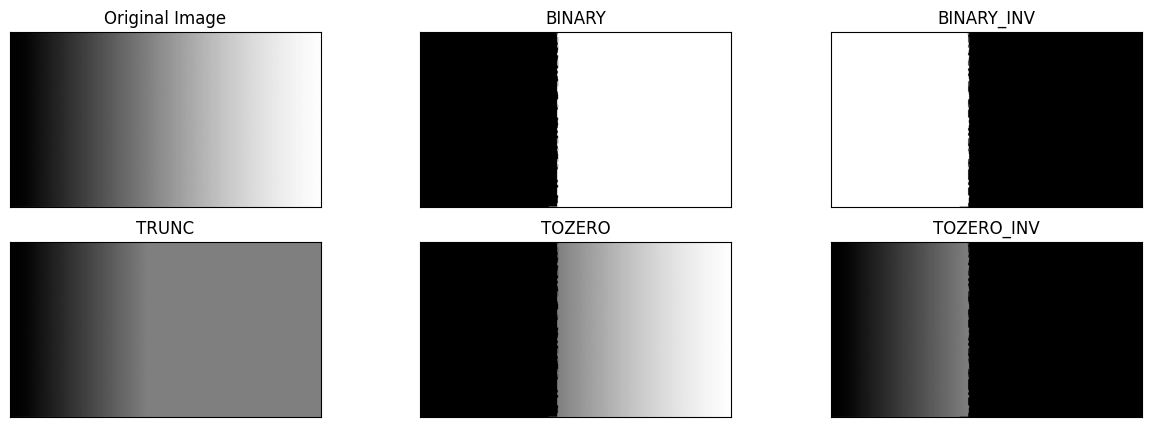

In [6]:
# Membuat Global Threshold
filename = ('/content/drive/MyDrive/PCVK/Images/gradient.jpg')

img = cv.imread(filename)

thresh = 127
maxval = 255


# 1. Binary Threshold
ret, thresh1 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_BINARY
)


# 2. Binary Inverse Threshold
ret, thresh2 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_BINARY_INV
)


# 3. Truncate Threshold
ret, thresh3 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_TRUNC
)


# 4. Threshold To Zero
ret, thresh4 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_TOZERO
)


# 5. Threshold To Zero Inverse
ret, thresh5 = cv.threshold(
    img,
    thresh,
    maxval,
    cv.THRESH_TOZERO_INV
)


titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]


images = [
    img,
    thresh1,
    thresh2,
    thresh3,
    thresh4,
    thresh5
]


plt.figure(figsize=(15,5))

for i in range(len(images)):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i],'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

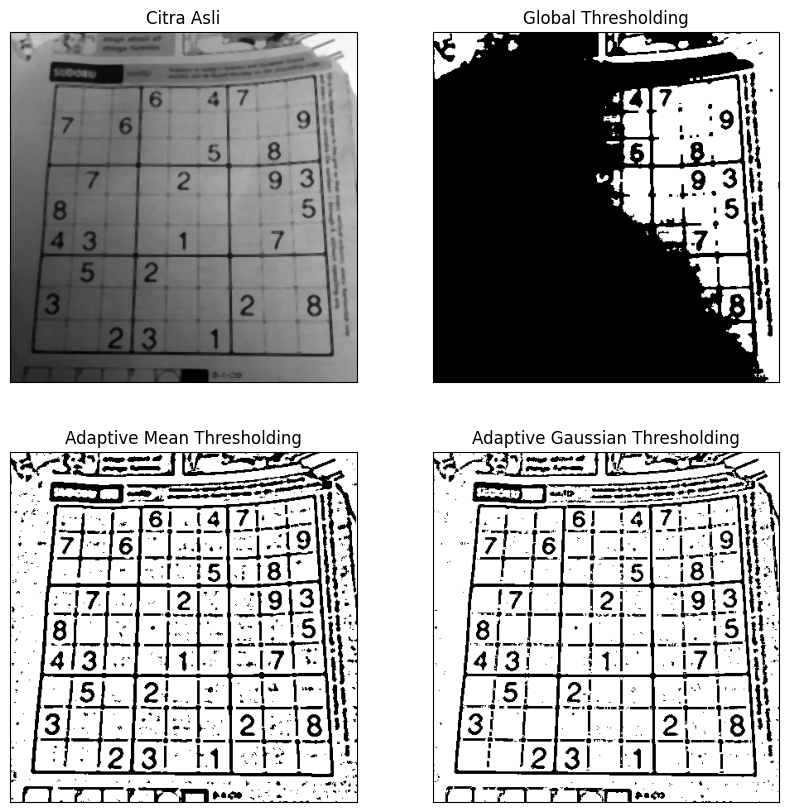

In [7]:
# Addaptive Threshold
import cv2 as cv
import matplotlib.pyplot as plt


filename = ('/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg')


citra = cv.medianBlur(
    cv.imread(filename),
    5
)


gray = cv.cvtColor(
    citra,
    cv.COLOR_BGR2GRAY
)


thresh = 127


# Global Threshold
ret, th1 = cv.threshold(
    gray,
    thresh,
    255,
    cv.THRESH_BINARY
)


# Adaptive Mean
th2 = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    11,
    2
)


# Adaptive Gaussian
th3 = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11,
    2
)


titles = [
    'Citra Asli',
    'Global Thresholding',
    'Adaptive Mean Thresholding',
    'Adaptive Gaussian Thresholding'
]


citra2 = [
    gray,
    th1,
    th2,
    th3
]


plt.figure(figsize=(10,10))

for i in range(len(citra2)):
    plt.subplot(2,2,i+1)
    plt.imshow(citra2[i],'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

Nilai Threshold Otsu Manual : 93


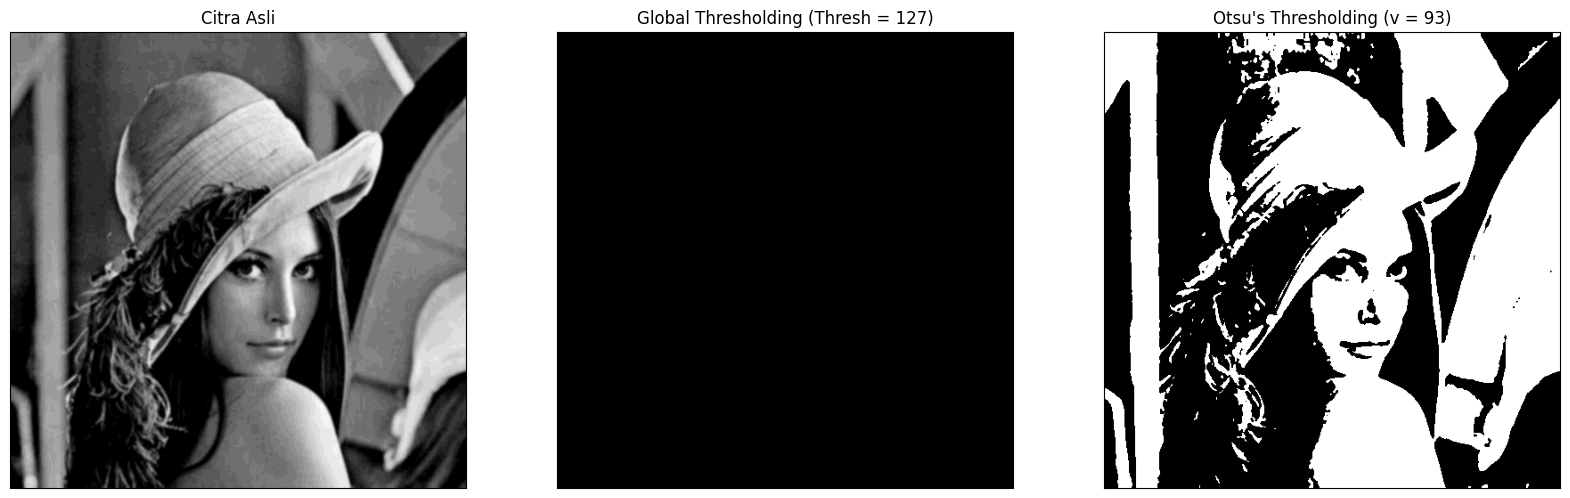

In [22]:
# A. OTSU THRESHOLDING TANPA MENGGUNAKAN LIBRARY
# Menggunakan image lena_gs_lc2.jpg



import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt



# Membaca citra grayscale

filename = '/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg'

img = cv.imread(filename, 0)



# Gaussian Blur

blur = cv.GaussianBlur(
    img,
    (5,5),
    0
)



# Nilai Global Threshold

thresh = 127



# Fungsi Otsu Manual

def otsu(gray):

    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number


    # Membuat histogram

    his, bins = np.histogram(
        gray,
        np.arange(0,257)
    )


    final_thresh = -1
    final_value = -1


    intensity_arr = np.arange(256)



    # Perulangan mencari threshold terbaik

    for t in bins[1:-1]:


        # Background dan foreground

        pcb = np.sum(his[:t])

        pcf = np.sum(his[t:])


        if pcb == 0 or pcf == 0:
            continue



        Wb = pcb * mean_weight

        Wf = pcf * mean_weight



        # Mean background

        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)



        # Mean foreground

        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)



        # Between class variance

        value = Wb * Wf * (mub - muf) ** 2



        if value > final_value:

            final_thresh = t

            final_value = value



    # Membuat citra biner

    final_img = gray.copy()


    final_img[gray > final_thresh] = 255

    final_img[gray <= final_thresh] = 0



    return final_img, final_thresh





# Menjalankan Otsu Manual

otsu_biner, otsu_thresh = otsu(blur)



print(
    "Nilai Threshold Otsu Manual :",
    otsu_thresh
)




# Global Threshold Library OpenCV

ret, th1 = cv.threshold(
    blur,
    thresh,
    255,
    cv.THRESH_BINARY
)





# Menampilkan hasil

x = (
    "Otsu's Thresholding (v = "
    + str(otsu_thresh)
    + ")"
)



titles = [

    'Citra Asli',

    'Global Thresholding (Thresh = '
    + str(thresh)
    + ')',

    x

]



citra3 = [

    blur,

    th1,

    otsu_biner

]




plt.figure(figsize=(20,15))



for i in range(len(citra3)):

    plt.subplot(1,3,i+1)

    plt.imshow(
        citra3[i],
        'gray'
    )

    plt.title(
        titles[i]
    )

    plt.xticks([])

    plt.yticks([])



plt.show()

##### Pertanyaan :
Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?

##### Jawaban :
Hasil Binary Thresholding menjadi hitam seluruhnya karena nilai Thresh = 127 terlalu tinggi dibandingkan nilai intensitas piksel citra Lena. Berdasarkan histogram, intensitas piksel Lena hanya berada pada rentang sekitar 85–108, sehingga tidak ada piksel yang memiliki nilai lebih besar dari 127. Akibatnya semua piksel dikategorikan sebagai background dan berubah menjadi 0 (hitam).

Agar citra Lena masih terlihat, nilai threshold harus diturunkan ke sekitar 90–100. Pada metode Otsu, nilai threshold yang diperoleh sekitar 92, sehingga hasil segmentasi masih dapat memisahkan objek dan background

Nilai Threshold Otsu KTP : 166
Nilai Threshold Otsu OpenCV : 165.0


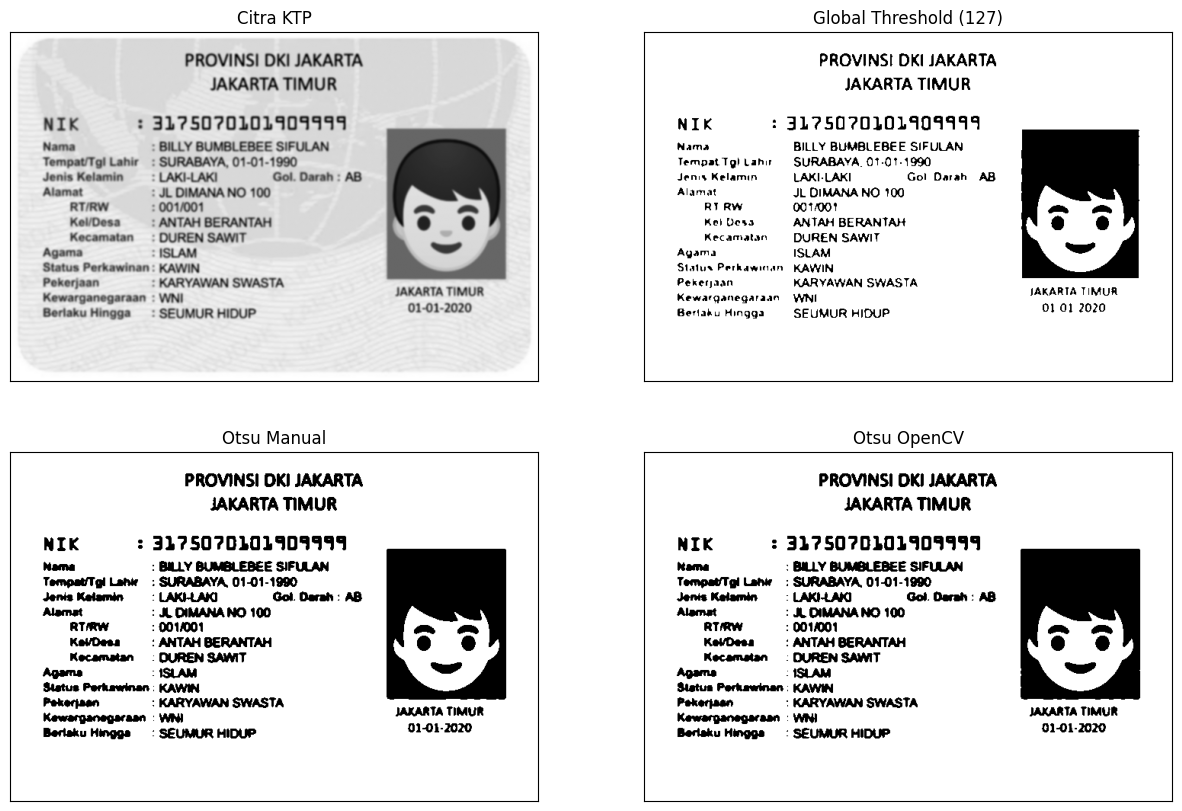

In [25]:
# ============================================================
# B. OTSU THRESHOLDING IMAGE KTP DARI GOOGLE DRIVE
# Membandingkan Global Threshold dan Otsu Threshold
# ============================================================


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt



# Membaca gambar KTP dari Google Drive

filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'

ktp = cv.imread(
    filename,
    0
)



# Gaussian Blur

blur = cv.GaussianBlur(
    ktp,
    (5,5),
    0
)



# Fungsi Otsu Manual

def otsu(gray):

    pixel_number = gray.shape[0] * gray.shape[1]

    mean_weight = 1.0 / pixel_number


    his, bins = np.histogram(
        gray,
        np.arange(0,257)
    )


    final_thresh = -1
    final_value = -1


    intensity_arr = np.arange(256)



    for t in bins[1:-1]:

        pcb = np.sum(
            his[:t]
        )

        pcf = np.sum(
            his[t:]
        )


        if pcb == 0 or pcf == 0:
            continue


        Wb = pcb * mean_weight

        Wf = pcf * mean_weight



        mub = np.sum(
            intensity_arr[:t] * his[:t]
        ) / float(pcb)



        muf = np.sum(
            intensity_arr[t:] * his[t:]
        ) / float(pcf)



        value = Wb * Wf * (mub - muf)**2



        if value > final_value:

            final_thresh = t

            final_value = value



    final_img = gray.copy()


    final_img[gray > final_thresh] = 255

    final_img[gray <= final_thresh] = 0



    return final_img, final_thresh





# Otsu Manual

otsu_biner, otsu_thresh = otsu(blur)


print(
    "Nilai Threshold Otsu KTP :",
    otsu_thresh
)




# Global Threshold

thresh = 127


ret, global_thresh = cv.threshold(
    blur,
    thresh,
    255,
    cv.THRESH_BINARY
)




# Otsu OpenCV

ret2, otsu_cv = cv.threshold(
    blur,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)


print(
    "Nilai Threshold Otsu OpenCV :",
    ret2
)





# Menampilkan hasil

titles = [

    "Citra KTP",

    "Global Threshold (127)",

    "Otsu Manual",

    "Otsu OpenCV"

]


images = [

    blur,

    global_thresh,

    otsu_biner,

    otsu_cv

]



plt.figure(figsize=(15,10))


for i in range(4):

    plt.subplot(2,2,i+1)

    plt.imshow(
        images[i],
        cmap='gray'
    )

    plt.title(
        titles[i]
    )

    plt.xticks([])

    plt.yticks([])



plt.show()

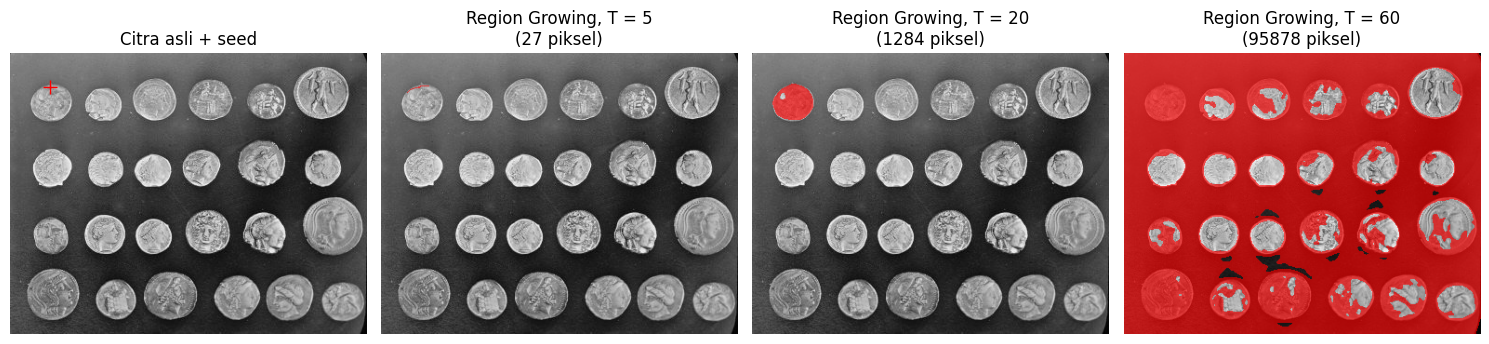

In [45]:

# 6A. SEGMENTASI BERBASIS REGION DATA.COINS()


import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from scipy.ndimage import gaussian_filter
from collections import deque

# Membaca citra
img = data.coins()

# Gaussian smoothing sesuai contoh
gray = gaussian_filter(img.astype(float), sigma=2)

# Seed sesuai modul
seed = (36, 43)

# Nilai toleransi
T_values = [5, 20, 60]


# Fungsi Region Growing manual
def region_growing(image, seed, T):

    h, w = image.shape
    region = np.zeros((h, w), dtype=bool)
    region[seed] = True

    antrian = deque([seed])

    jumlah = 1
    total = float(image[seed])

    while antrian:

        y, x = antrian.popleft()

        # Pemeriksaan 8 tetangga
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):

                if dy == 0 and dx == 0:
                    continue

                ny, nx = y + dy, x + dx

                if not (0 <= ny < h and 0 <= nx < w):
                    continue

                if region[ny, nx]:
                    continue

                rata_rata = total / jumlah

                if abs(image[ny, nx] - rata_rata) <= T:

                    region[ny, nx] = True
                    antrian.append((ny, nx))

                    total += float(image[ny, nx])
                    jumlah += 1

    return region



# Menampilkan 4 gambar sesuai contoh modul
plt.figure(figsize=(15, 4))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=10)
plt.title("Citra asli + seed")
plt.axis('off')


# Hasil Region Growing
for i, T in enumerate(T_values):

    region = region_growing(gray, seed, T)

    # Overlay merah
    overlay = np.zeros((*img.shape, 4))
    overlay[:, :, 0] = 1
    overlay[:, :, 3] = region * 0.65

    plt.subplot(1, 4, i + 2)
    plt.imshow(img, cmap='gray')
    plt.imshow(overlay)

    plt.title(
        f"Region Growing, T = {T}\n"
        f"({np.sum(region)} piksel)"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()


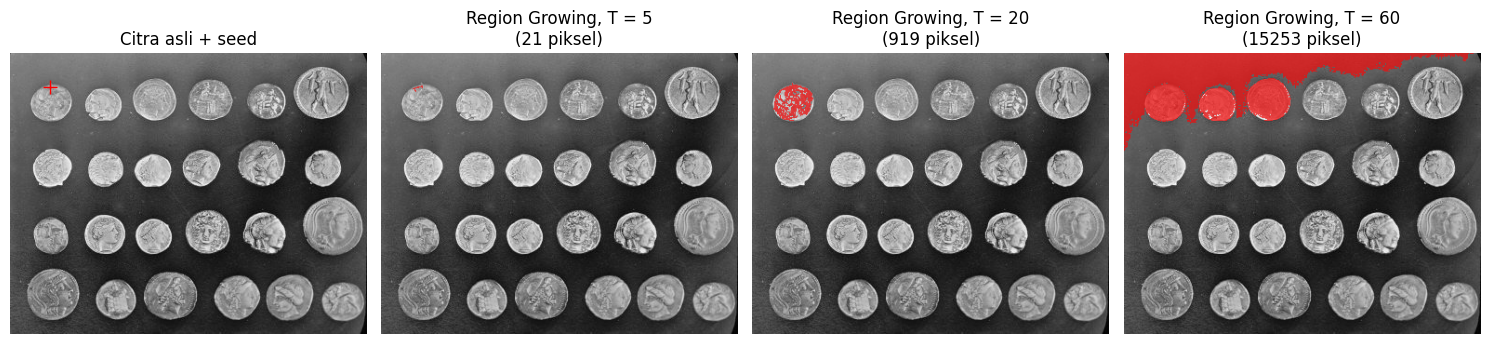

In [39]:
# 6B. SEGMENTASI MENGGUNAKAN SKIMAGE.SEGMENTATION.FLOOD()

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# Membaca citra
gray = data.coins()

# Seed sesuai hasil gambar modul
seed = (36, 43)

# Nilai toleransi
T_values = [5, 20, 60]

# Menampilkan 4 gambar
plt.figure(figsize=(15, 4))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=10)
plt.title("Citra asli + seed")
plt.axis('off')

# Segmentasi menggunakan flood()
for i, T in enumerate(T_values):

    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    # Overlay merah
    overlay = np.zeros((*gray.shape, 4))
    overlay[:, :, 0] = 1
    overlay[:, :, 3] = region * 0.65

    plt.subplot(1, 4, i + 2)
    plt.imshow(gray, cmap='gray')
    plt.imshow(overlay)

    plt.title(
        f"Region Growing, T = {T}\n"
        f"({np.sum(region)} piksel)"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()


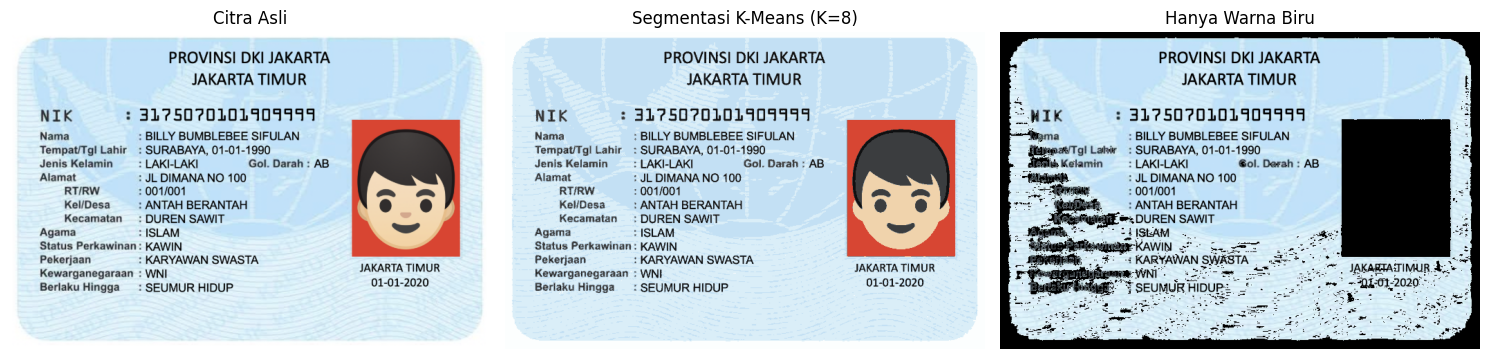

In [50]:
# 7. SEGMENTASI WARNA BIRU PADA CITRA KTP
# Menggunakan K-Means dan HSV


import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt


# 1. MEMBACA CITRA KTP

filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'

# Membaca citra dan mengubah BGR menjadi RGB
img = cv.imread(filename)

if img is None:
    raise FileNotFoundError("File gambar KTP tidak ditemukan!")

img = cv.cvtColor(img, cv.COLOR_BGR2RGB)


# 2. SEGMENTASI MENGGUNAKAN K-MEANS (K = 8)

# Mengubah citra menjadi array piksel
Z = np.float32(img.reshape((-1, 3)))

# Menentukan jumlah cluster
K = 8

# Kriteria penghentian K-Means
criteria = (
    cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Menjalankan K-Means
_, labels, centers = cv.kmeans(
    Z,
    K,
    None,
    criteria,
    10,
    cv.KMEANS_PP_CENTERS
)

# Membentuk citra hasil segmentasi K-Means
centers = np.uint8(centers)
segmented_img = centers[labels.flatten()].reshape(img.shape)



# 3. SEGMENTASI WARNA BIRU MENGGUNAKAN HSV

# Konversi citra RGB menjadi HSV
hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)

# Memisahkan komponen Hue, Saturation, dan Value
H, S, V = cv.split(hsv)

# Menentukan rentang warna biru sesuai modul
kelompok_biru = (
    (H >= 85) & (H <= 130) &
    (S >= 25) & (V >= 40)
)

# Menampilkan hanya piksel berwarna biru
hasil_biru = np.zeros_like(img)
hasil_biru[kelompok_biru] = img[kelompok_biru]


# MENAMPILKAN HASIL SEGMENTASI

titles = [
    "Citra Asli",
    "Segmentasi K-Means (K=8)",
    "Hanya Warna Biru"
]

images = [img, segmented_img, hasil_biru]

plt.figure(figsize=(15, 5))

for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


Tugas Kelompok

In [51]:
# Instalasi Tesseract dan model bahasa Indonesia
!apt-get update -qq
!apt-get install -y -qq tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


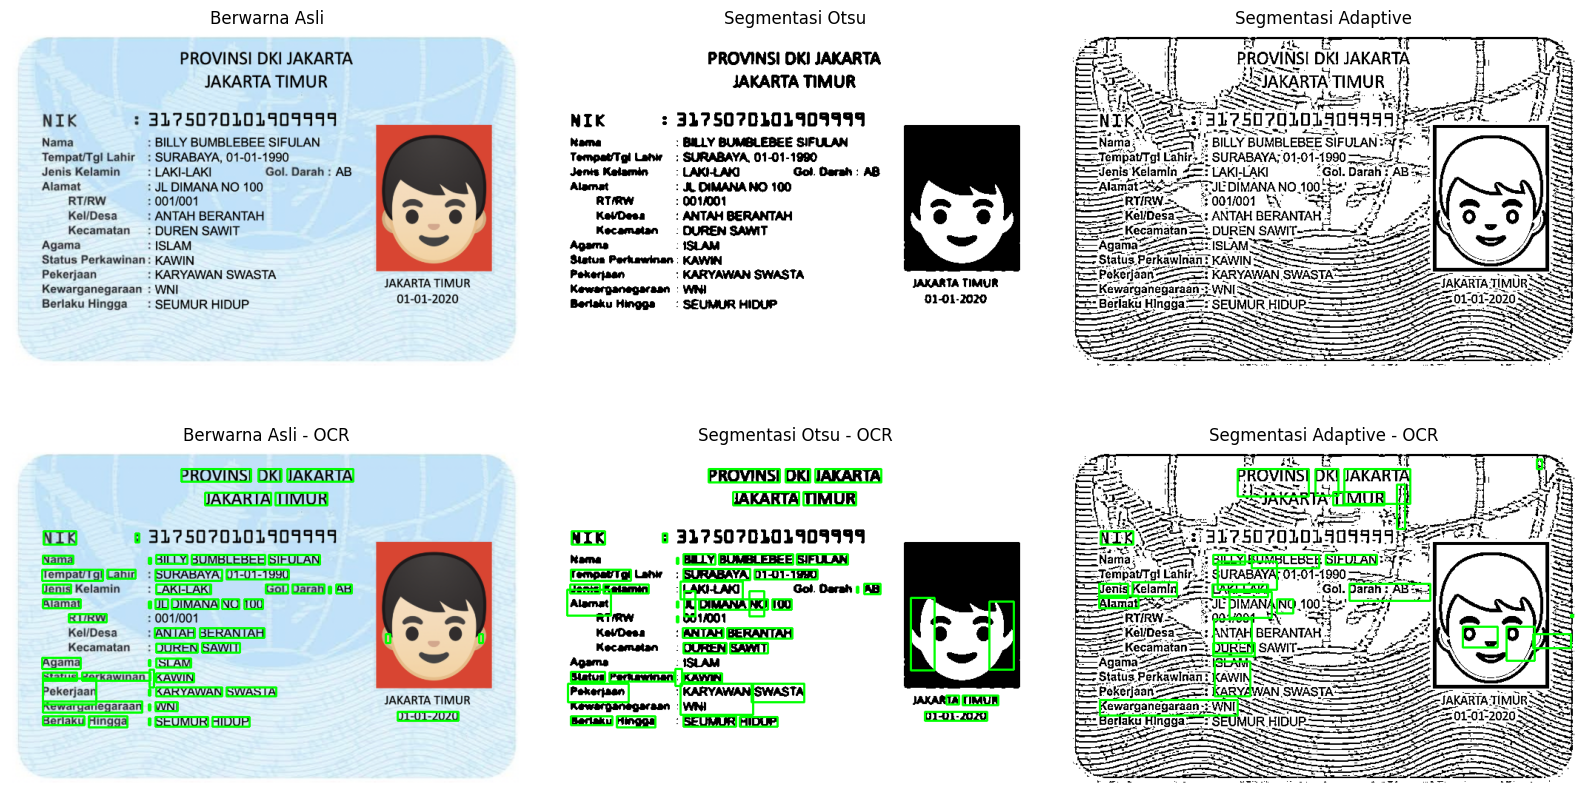


HASIL OCR: Berwarna Asli
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31750?0101901411
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KellDesa —— : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT t
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI SIata TOR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


HASIL OCR: Segmentasi Otsu
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 31?507D101909919
kama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgi Lahu: SURABAYA, 01-01-1900
Jenis Kelamin LAKI-LAKI Gol. Daerah : AB
Alamat : JL DIMANA NO 100

RTRW : 0017001

KevDesa —: ANTAH BERANTAH d z )

Kecamatan: DUREN SAWIT
Status Perkawinan : KAWIN
Pekerjaan aan 8 KARYAWAN SWASTA TA TIMUR
Berlaku Hingga —: SEUMUR HIDUP 01-01-2020


HASIL OCR: Segmentasi Adaptive
sr (7 bg pr Ka it 3
“5 | PROVINSI DKI JAKARTA Eh 1
ea SSJAKARTA TIMUR | Ta!

Sm AN kt aah Bere IS
Pi Ae EA at Aha SE

In [52]:

# ============================================================
# D2. TUGAS KELOMPOK - OCR CITRA KTP
# ============================================================

import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from google.colab import drive
from IPython.display import display

# ============================================================
# 1. MEMBACA CITRA KTP
# ============================================================

drive.mount('/content/drive')

filename = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'

img = cv.imread(filename)

if img is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan!")

rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)


# ============================================================
# 2. SEGMENTASI OTSU DAN ADAPTIVE THRESHOLD
# ============================================================

# Otsu Thresholding
blur = cv.GaussianBlur(gray, (5, 5), 0)

nilai_otsu, otsu = cv.threshold(
    blur, 0, 255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# Adaptive Thresholding
adaptive = cv.adaptiveThreshold(
    gray, 255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11, 2
)

# Tiga citra dengan ukuran sama
citra = {
    "Berwarna Asli": rgb,
    "Segmentasi Otsu": otsu,
    "Segmentasi Adaptive": adaptive
}


# ============================================================
# 3. OCR MENGGUNAKAN PYTESSERACT
# ============================================================

config = '--oem 3 --psm 6'
hasil = {}

for nama, gambar in citra.items():

    teks = pytesseract.image_to_string(
        gambar,
        lang='ind',
        config=config
    )

    data_ocr = pytesseract.image_to_data(
        gambar,
        lang='ind',
        config=config,
        output_type=pytesseract.Output.DICT
    )

    hasil[nama] = {
        "teks": teks,
        "data": data_ocr
    }


# ============================================================
# 4. MENAMPILKAN CITRA DAN KOTAK HIJAU
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for i, (nama, gambar) in enumerate(citra.items()):

    # Baris pertama: citra masukan
    axes[0, i].imshow(
        gambar,
        cmap='gray' if gambar.ndim == 2 else None
    )

    axes[0, i].set_title(nama)
    axes[0, i].axis('off')

    # Baris kedua: hasil OCR dengan kotak hijau
    if gambar.ndim == 2:
        box_img = cv.cvtColor(gambar, cv.COLOR_GRAY2RGB)
    else:
        box_img = gambar.copy()

    data_ocr = hasil[nama]["data"]

    for j, teks in enumerate(data_ocr["text"]):

        confidence = float(data_ocr["conf"][j])

        if teks.strip() and confidence > 60:

            x = data_ocr["left"][j]
            y = data_ocr["top"][j]
            w = data_ocr["width"][j]
            h = data_ocr["height"][j]

            cv.rectangle(
                box_img,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

    axes[1, i].imshow(box_img)
    axes[1, i].set_title(nama + " - OCR")
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


# ============================================================
# 5. MENAMPILKAN HASIL PEMBACAAN TEKS
# ============================================================

for nama in citra:

    print("\n====================================")
    print("HASIL OCR:", nama)
    print("====================================")

    print(hasil[nama]["teks"])

print("\nThreshold Otsu:", nilai_otsu)
